# Resultados do experimento completo

Este caderno lê somente os artefatos auditados da matriz de 390 treinamentos. Ele não recalibra modelos nem altera resultados.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd()
PASTA = RAIZ / 'resultados' / 'completo'
validacao = json.loads((PASTA / 'validacao_artefatos.json').read_text(encoding='utf-8'))
assert validacao['valid'] and validacao['found_runs'] == 390
validacao

{'modo': 'completo',
 'expected_runs': 390,
 'found_runs': 390,
 'expected_masks': 120,
 'errors': [],
 'valid': True}

## Ambiente, base e configuração congelada

In [2]:
manifesto = json.loads((RAIZ / 'resultados' / 'manifesto_execucao.json').read_text(encoding='utf-8'))
calibracao = json.loads((RAIZ / 'modelos' / 'configuracao_congelada.json').read_text(encoding='utf-8'))
display(pd.Series(manifesto['environment'], name='versão').to_frame())
display(pd.DataFrame({
    nome: {
        'Macro-F1 CV': dados['best_cv_macro_f1'],
        'limiar congelado': dados['threshold'],
        'Macro-F1 validação': dados['validation_macro_f1'],
        'parâmetros': str(dados['best_parameters']),
    } for nome, dados in calibracao['models'].items()
}).T)

,versão
python,3.13.15
platform,Windows-10-10.0.19045-SP0
numpy,2.3.4
pandas,2.3.3
scikit_learn,1.7.2
xgboost,3.1.1
shap,0.54.1
scipy,1.16.3
matplotlib,3.10.7


,Macro-F1 CV,limiar congelado,Macro-F1 validação,parâmetros
logistic_regression,0.612577,0.21,0.693568,"{'C': 1.0, 'class_weight': None}"
random_forest,0.689049,0.55,0.714842,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
xgboost,0.646139,0.27,0.703472,"{'colsample_bytree': 0.8, 'learning_rate': 0.1..."


## Resultados principais no nível de 30%

In [3]:
resultados = pd.read_csv(PASTA / 'tabela_resultados_principais.csv')
colunas = ['modelo', 'degradacao', 'macro_f1_media', 'delta_macro_f1_medio',
           'delta_macro_f1_ic95_inferior', 'delta_macro_f1_ic95_superior',
           'shap_spearman_global_medio', 'shap_l1_global_media',
           'shap_cosseno_local_medio']
resultados.loc[resultados['nivel'].eq(0.30), colunas].round(4)

,modelo,degradacao,macro_f1_media,delta_macro_f1_medio,delta_macro_f1_ic95_inferior,delta_macro_f1_ic95_superior,shap_spearman_global_medio,shap_l1_global_media,shap_cosseno_local_medio
3,logistic_regression,attribute_errors,0.6778,-0.0241,-0.0257,-0.0225,0.8464,0.4243,0.7698
7,logistic_regression,label_noise,0.1048,-0.5971,-0.5980,-0.5963,0.7721,0.4897,0.8097
11,logistic_regression,missing_values,0.6902,-0.0117,-0.0131,-0.0103,0.9382,0.1420,0.9671
15,random_forest,attribute_errors,0.6702,-0.0388,-0.0423,-0.0357,0.7989,0.3538,0.7582
19,random_forest,label_noise,0.6579,-0.0511,-0.0544,-0.0477,0.7329,0.3507,0.5968
23,random_forest,missing_values,0.7024,-0.0067,-0.0083,-0.0049,0.9561,0.1259,0.9175
27,xgboost,attribute_errors,0.6818,-0.0236,-0.0270,-0.0206,0.7979,0.2775,0.5840
31,xgboost,label_noise,0.3251,-0.3803,-0.3859,-0.3754,0.7168,0.3814,0.3681
35,xgboost,missing_values,0.6935,-0.0119,-0.0144,-0.0096,0.9314,0.1271,0.7715


## Avaliação pré-registrada das hipóteses

In [4]:
hipoteses = json.loads((PASTA / 'avaliacao_hipoteses.json').read_text(encoding='utf-8'))
pd.DataFrame([
    {'hipótese': chave, 'confirmada': valor['confirmed']}
    for chave, valor in hipoteses.items()
])

,hipótese,confirmada
0,H1,True
1,H2,False
2,H3,True


## Testes estatísticos

In [5]:
testes = pd.read_csv(PASTA / 'testes_estatisticos.csv')
pd.Series({
    'comparações registradas': len(testes),
    'pós-testes executados após Friedman significativo': int(testes['posthoc_performed'].sum()),
    'comparações significativas após Holm': int(testes['significativo_005'].sum()),
}).to_frame('quantidade')

,quantidade
comparações registradas,324
pós-testes executados após Friedman significativo,316
comparações significativas após Holm,276


## Figuras geradas automaticamente

macro_f1_por_nivel.png


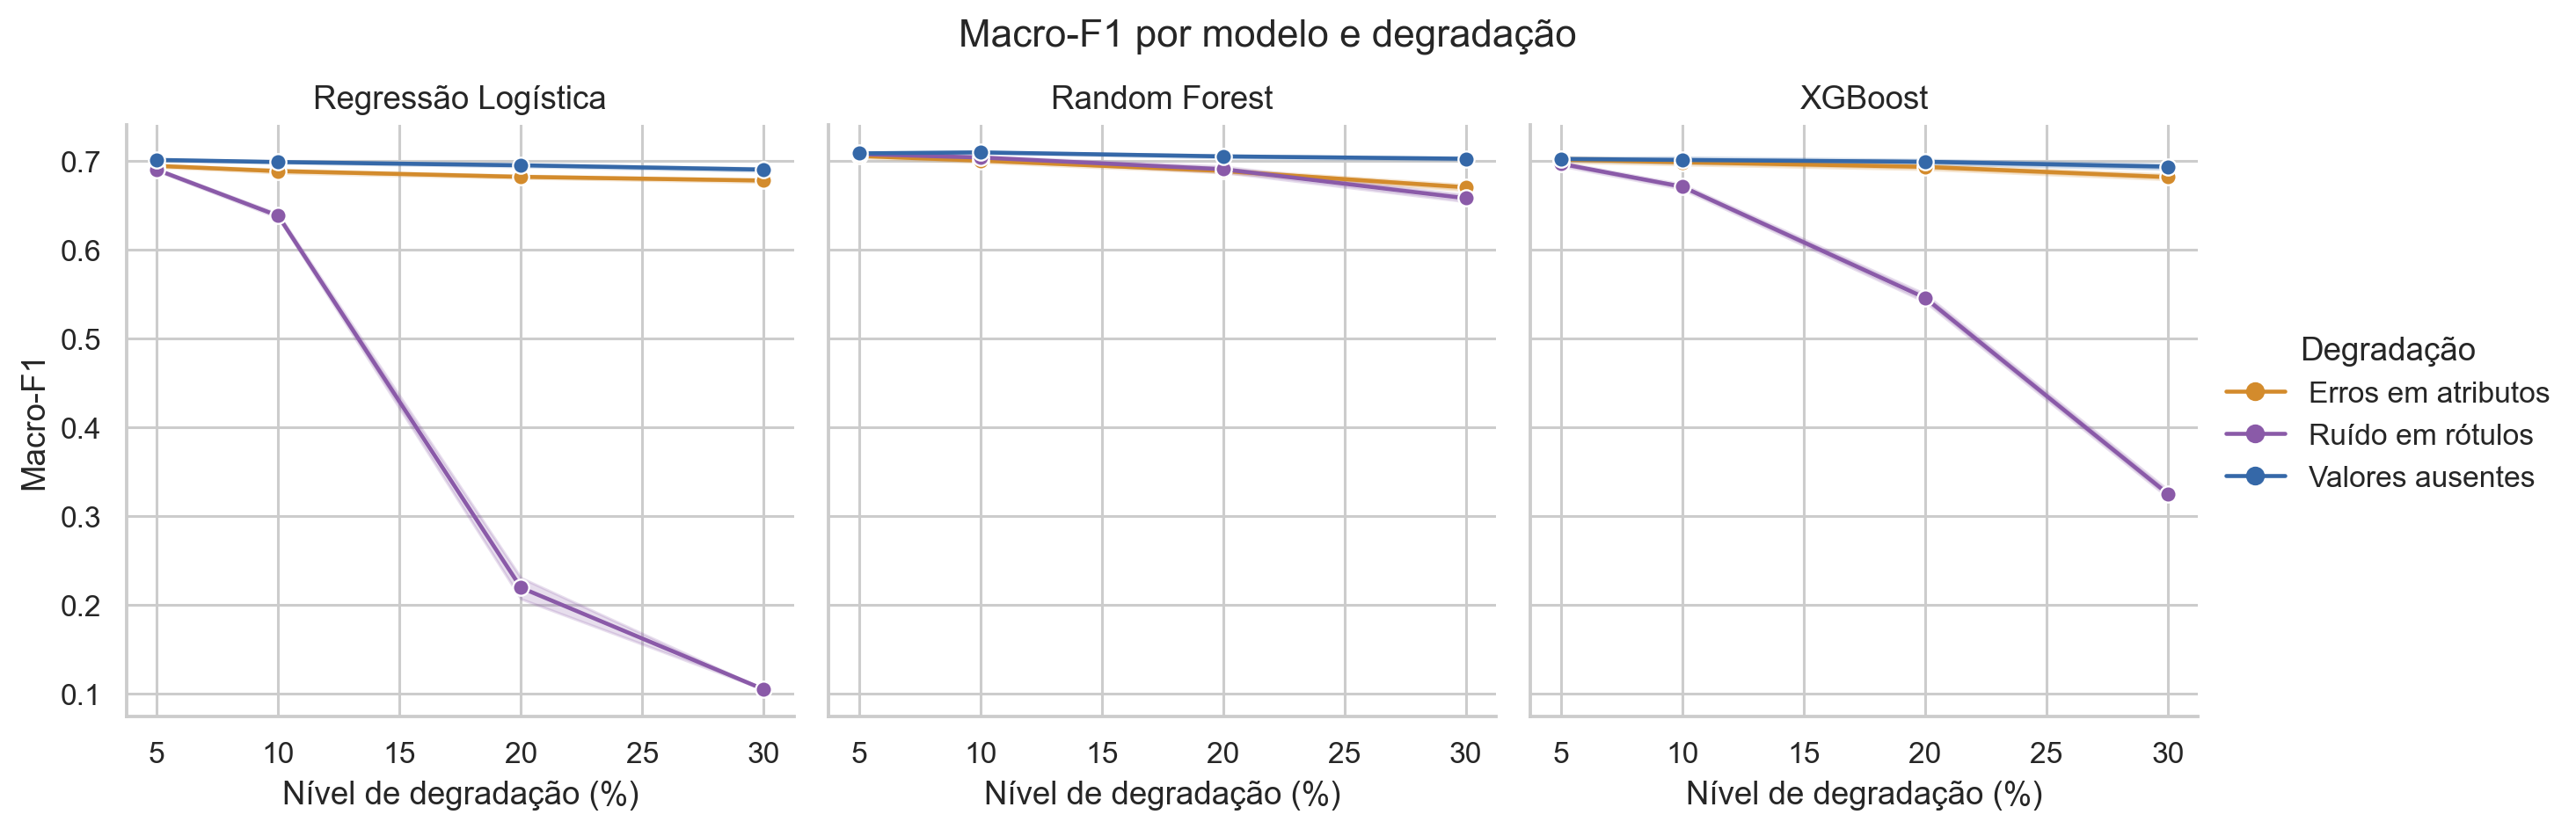

pr_auc_por_nivel.png


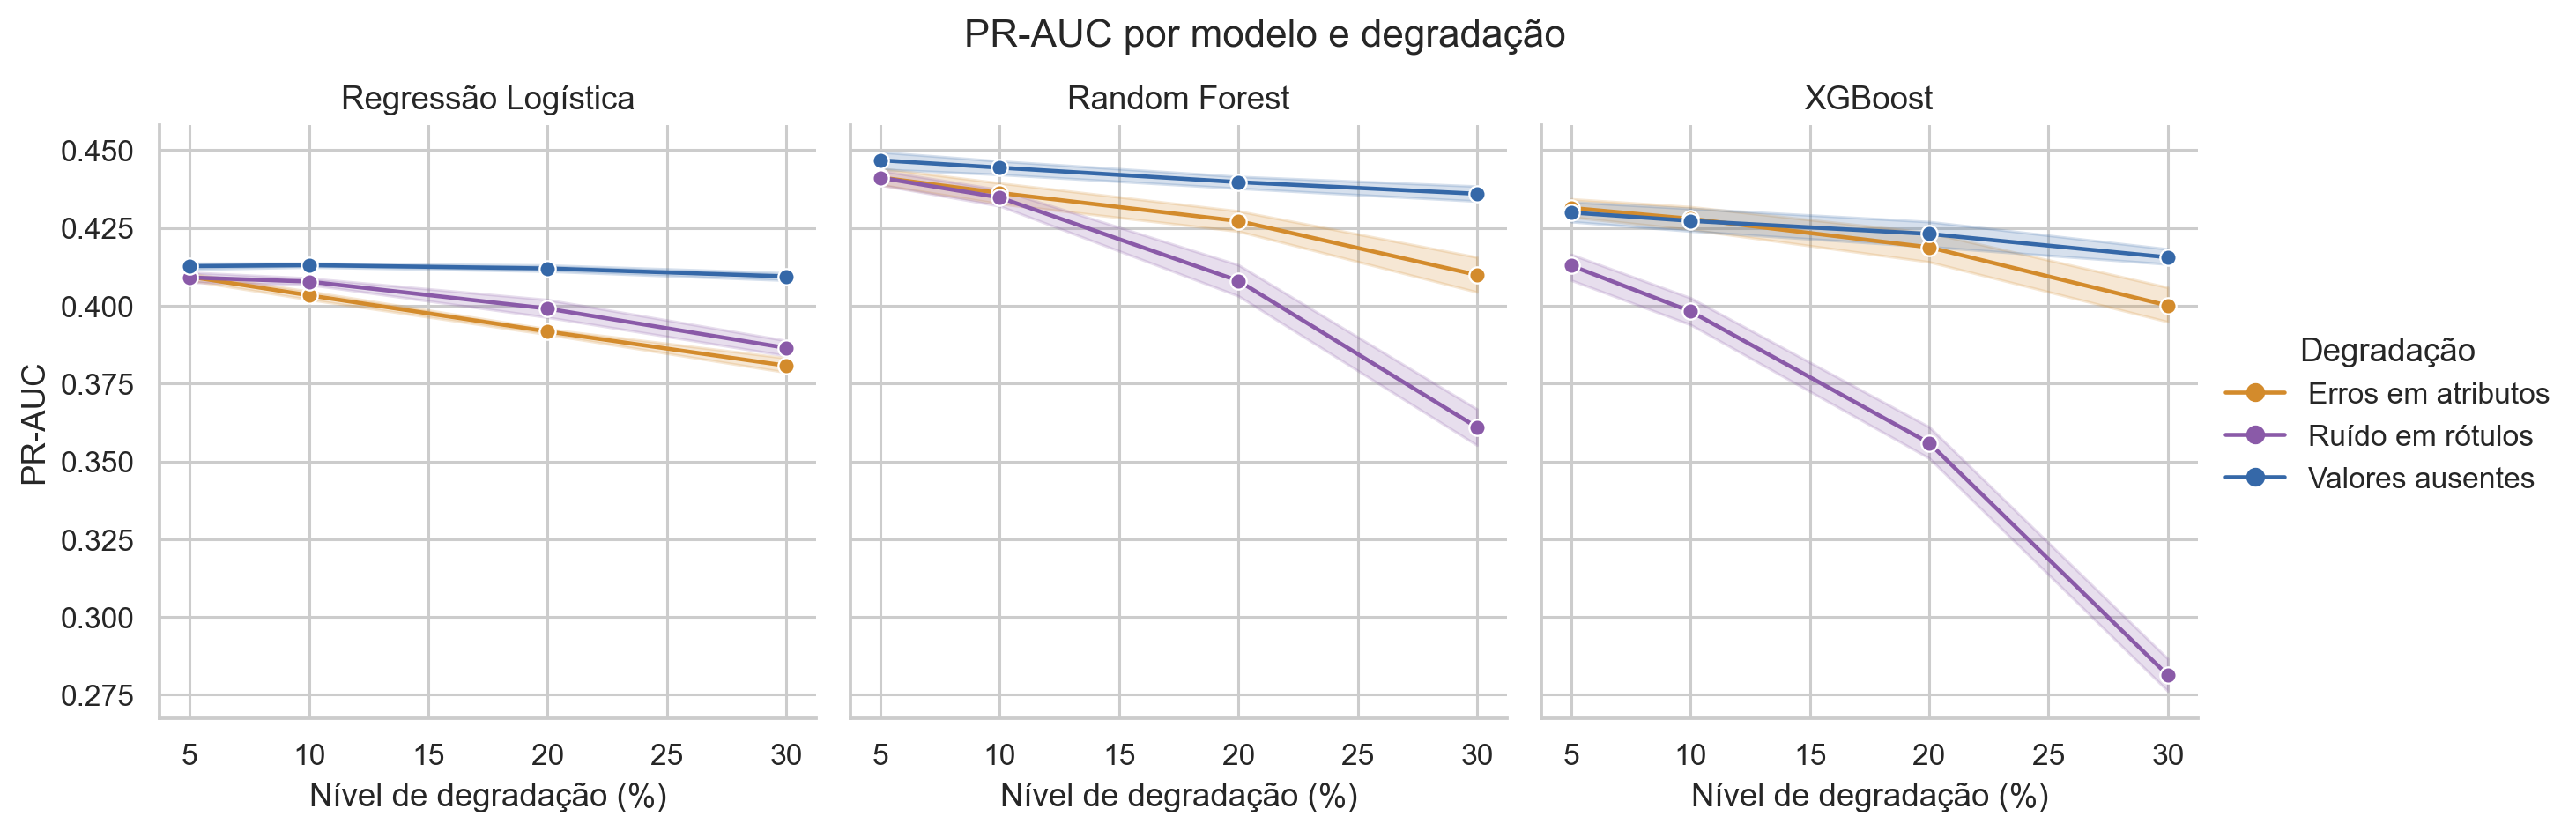

shap_global_spearman_por_nivel.png


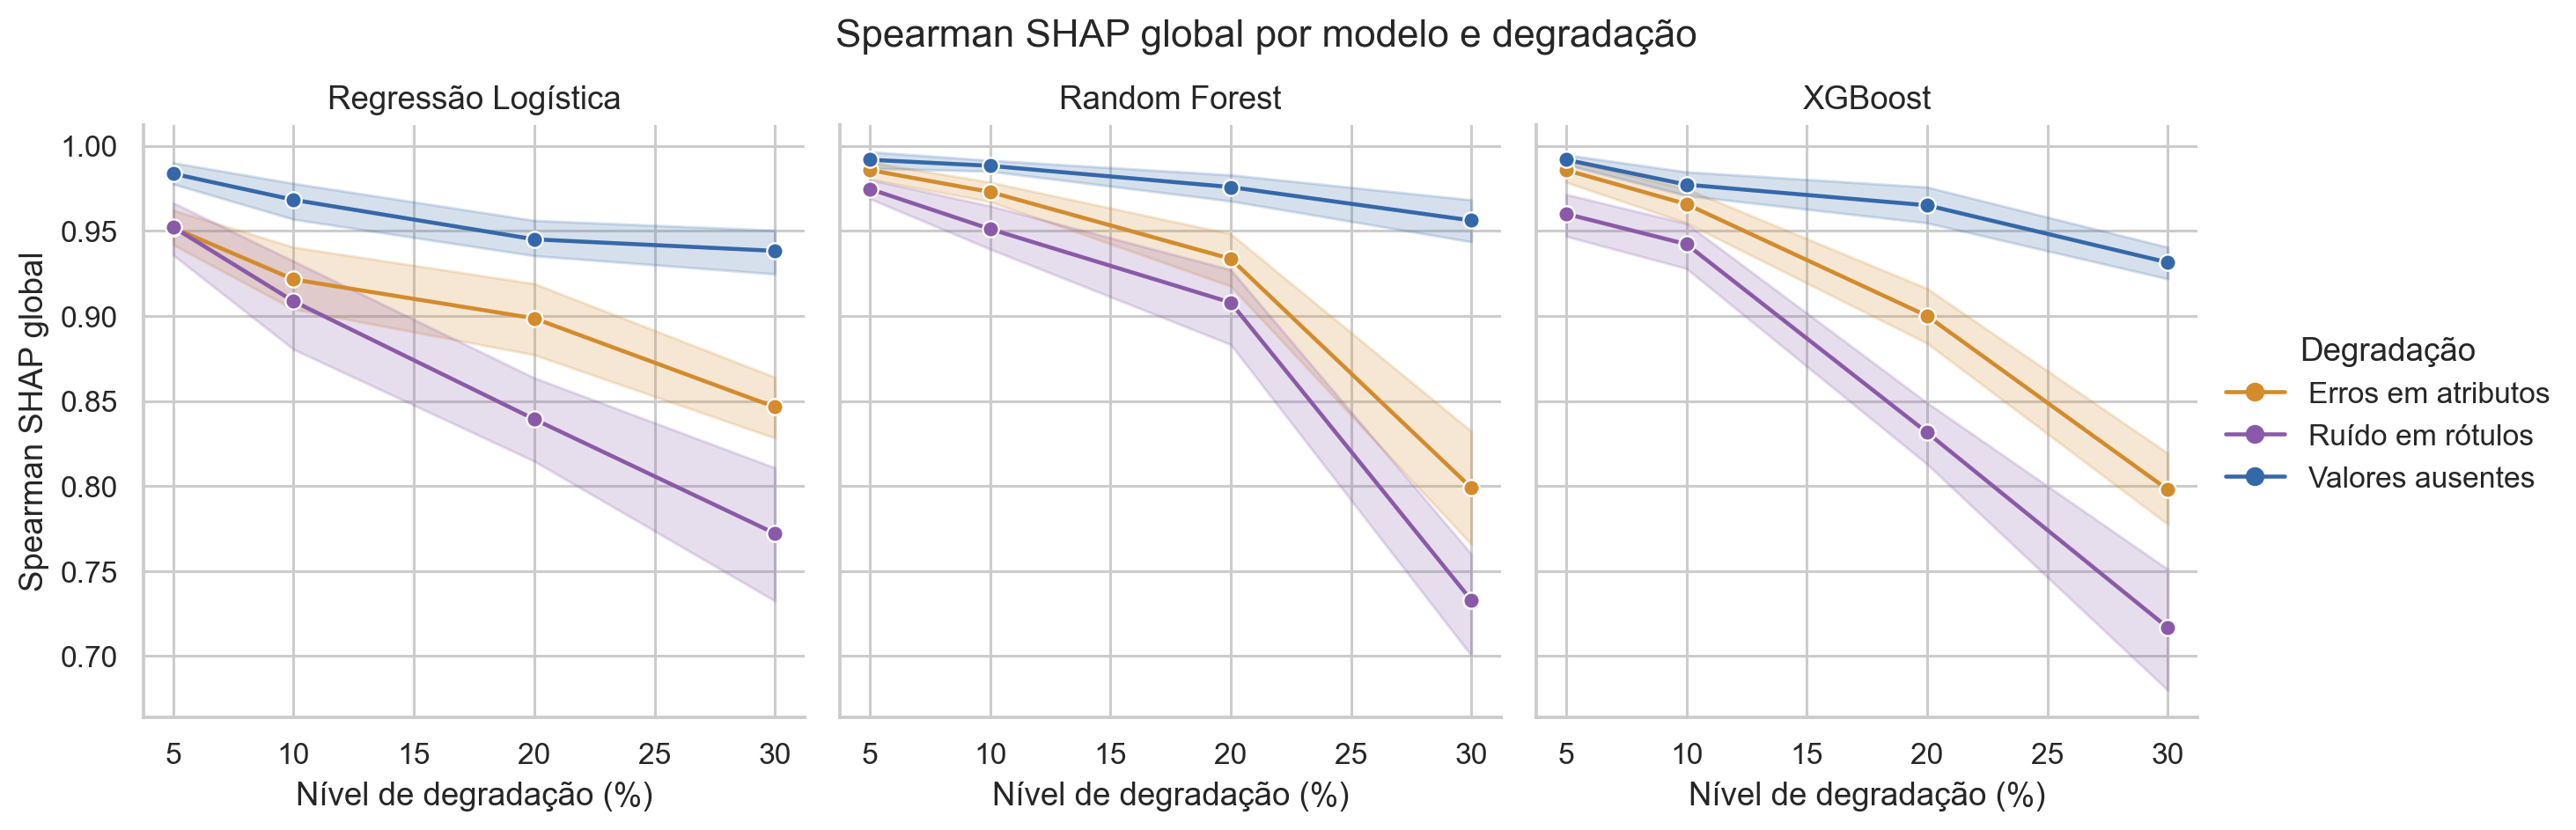

shap_local_cosine_mean_por_nivel.png


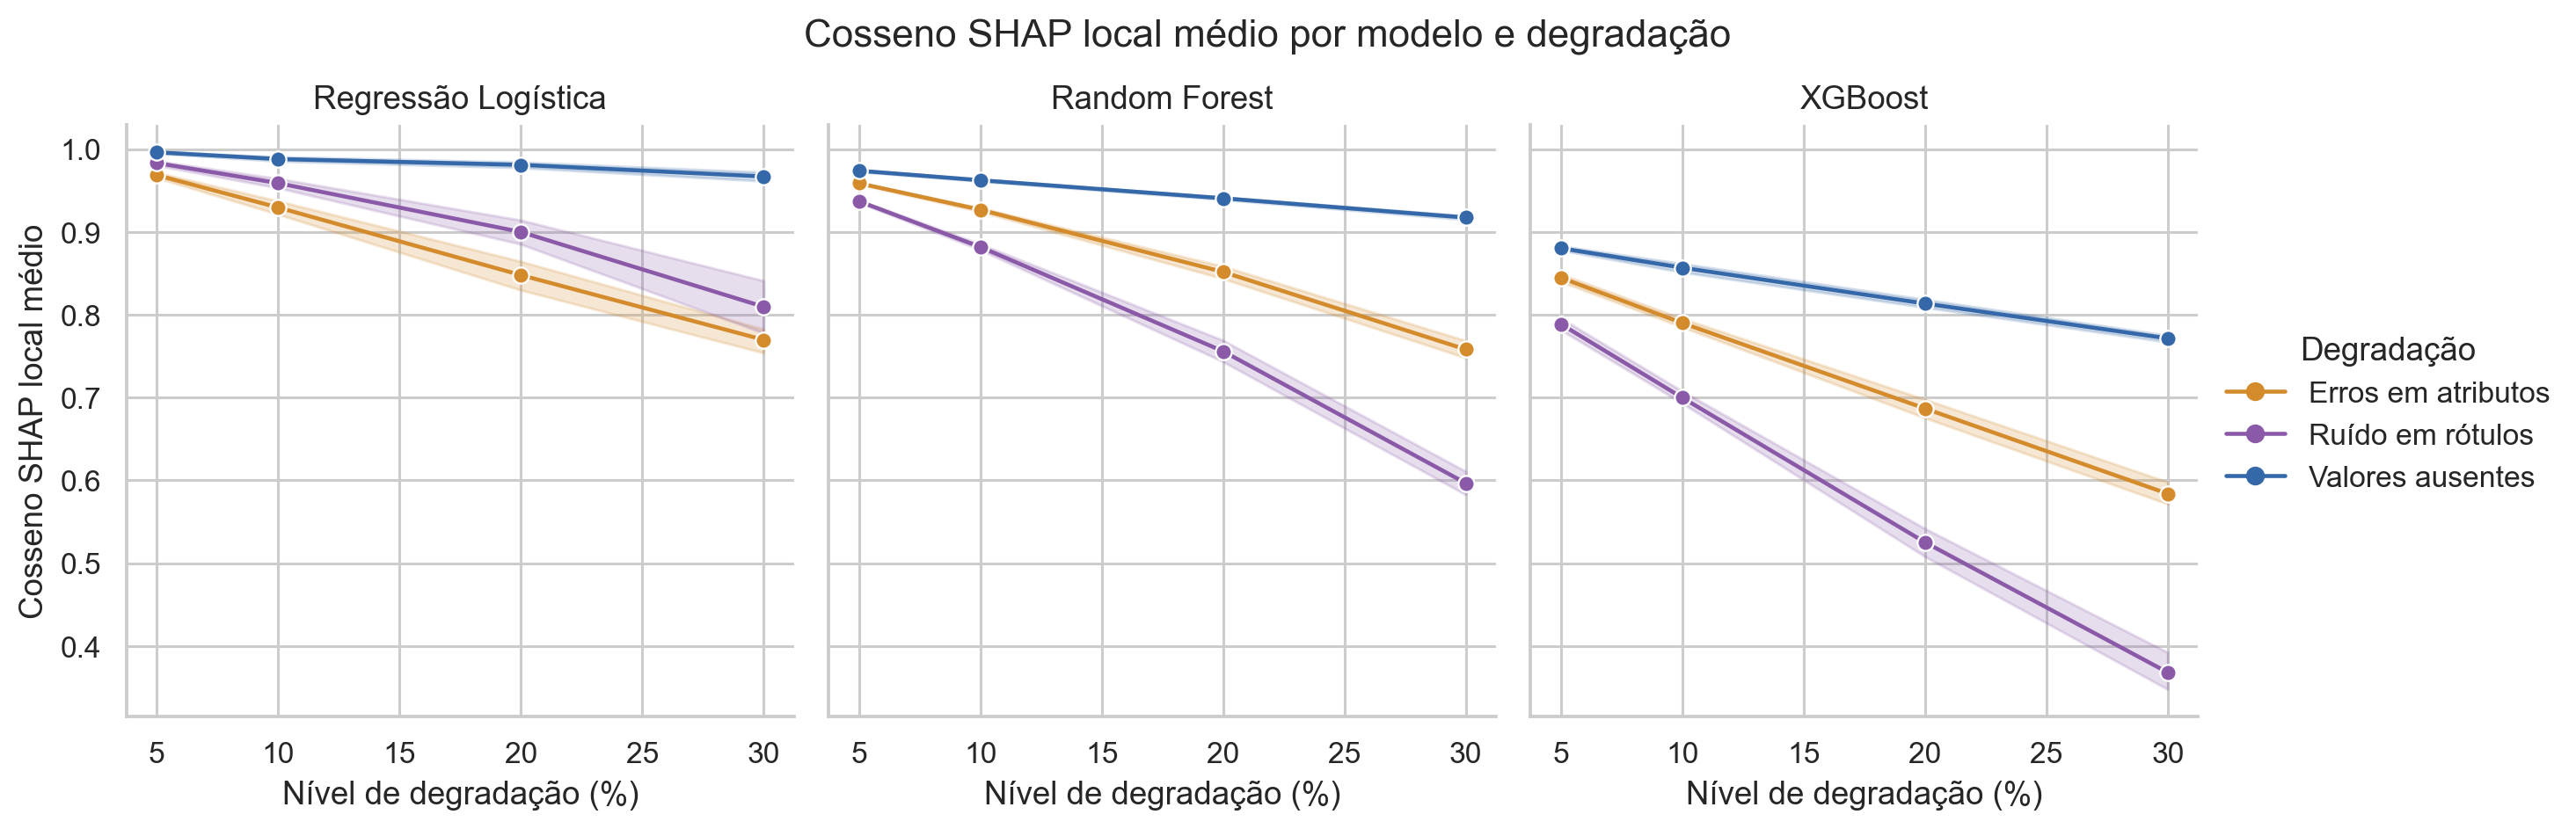

desempenho_vs_estabilidade.png


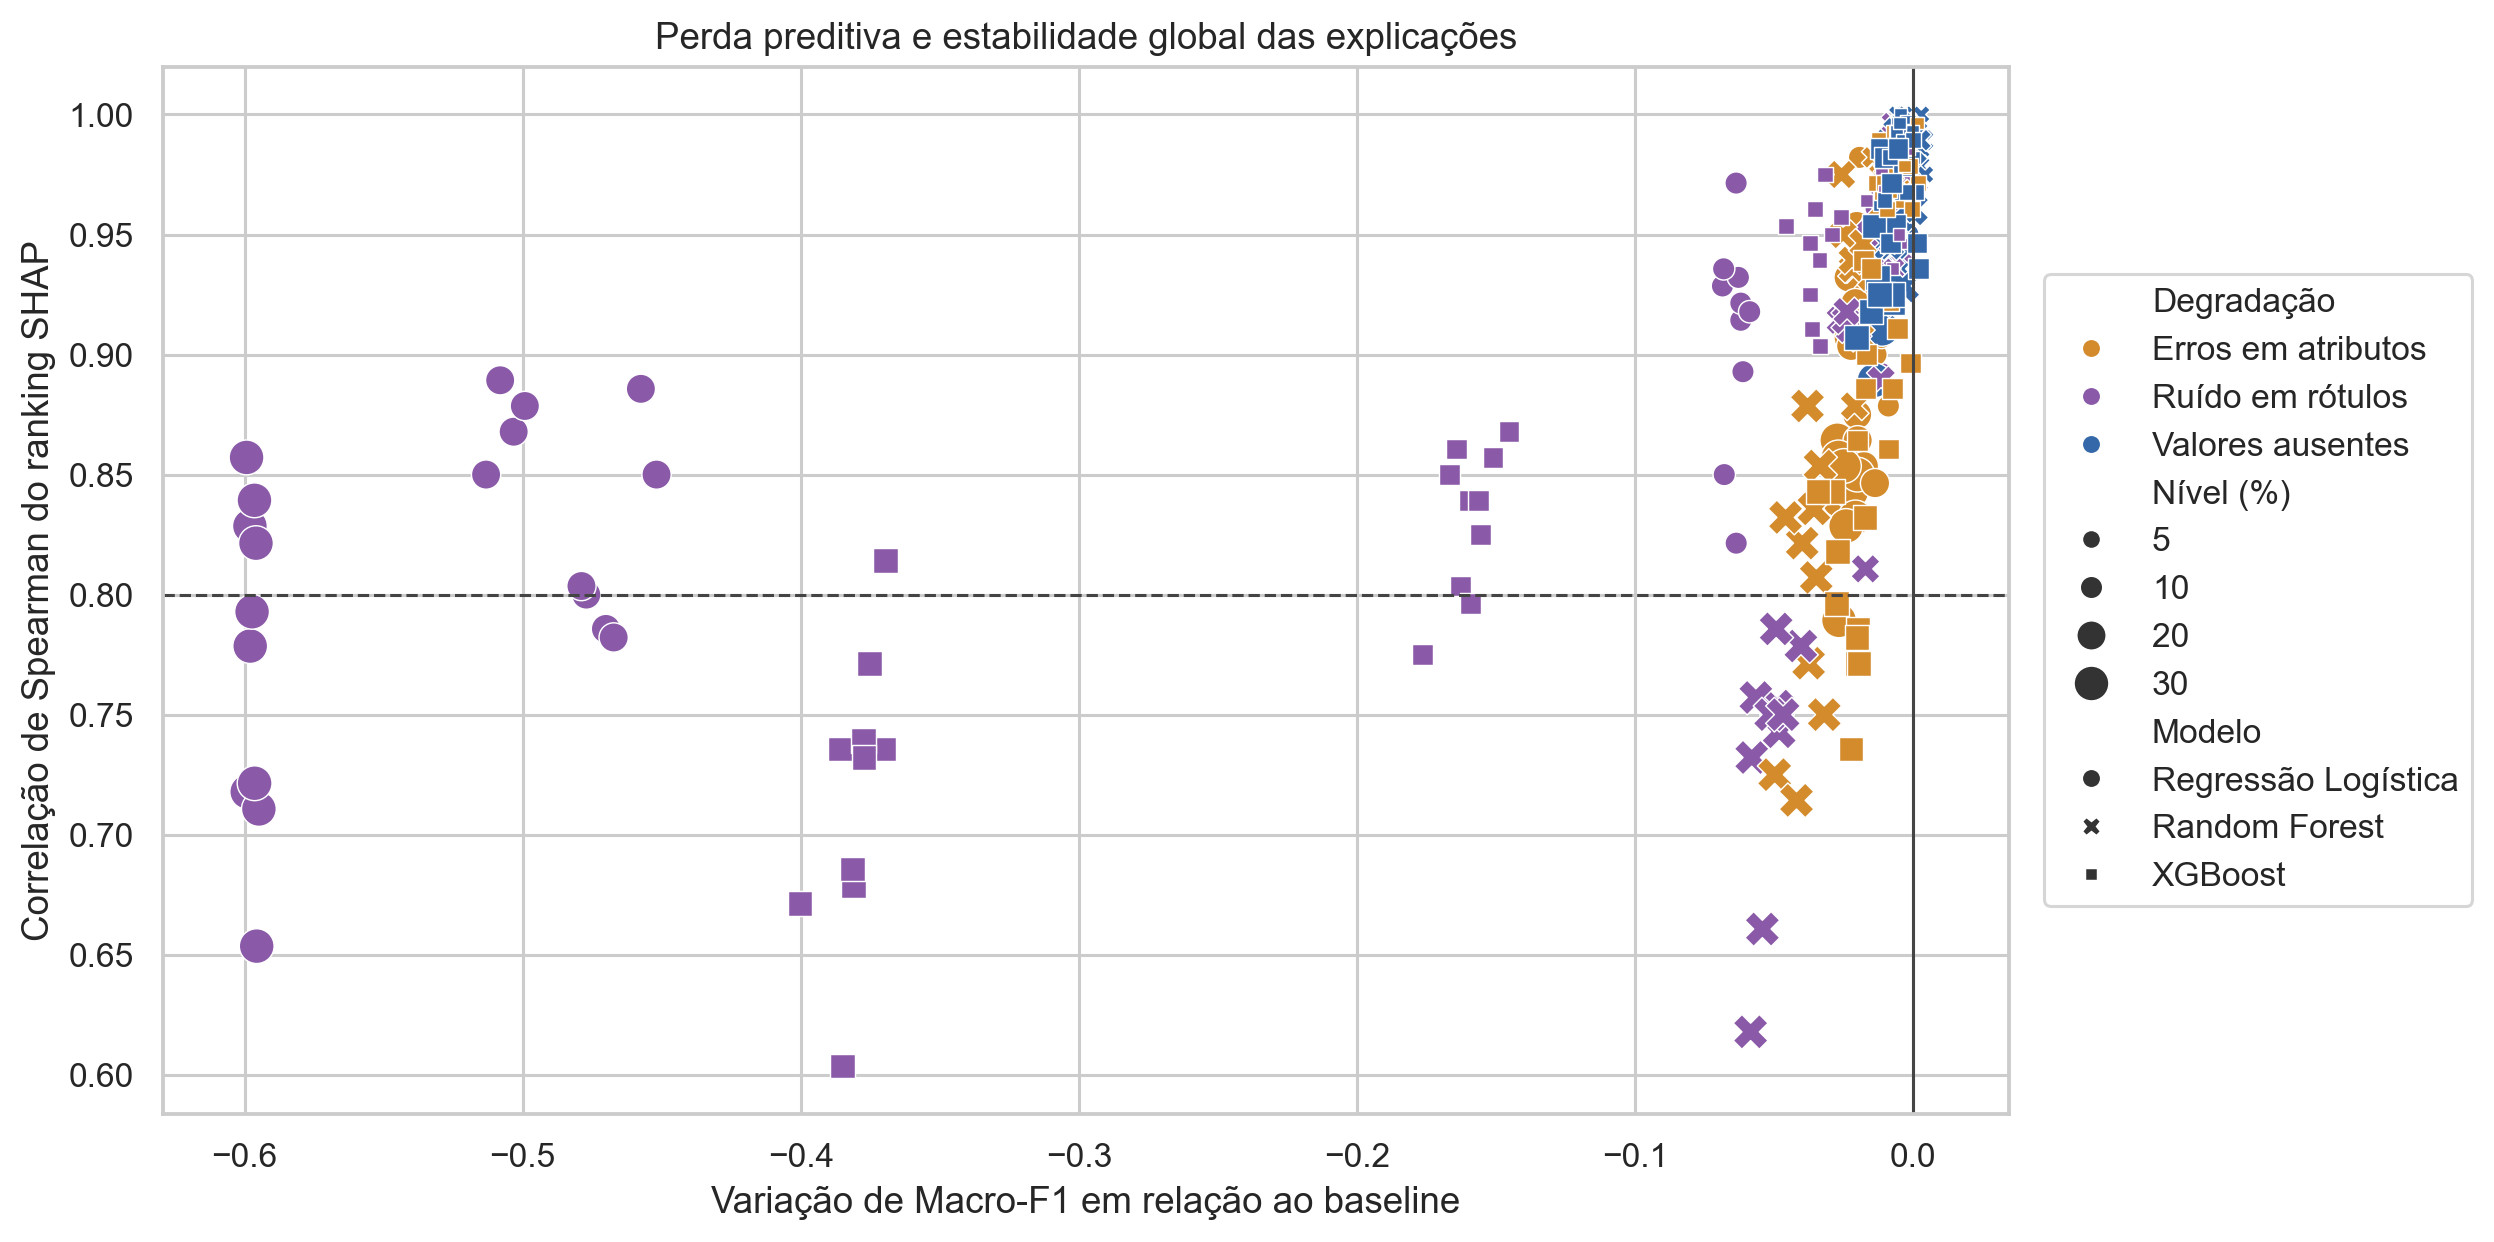

In [6]:
for nome in [
    'macro_f1_por_nivel.png', 'pr_auc_por_nivel.png',
    'shap_global_spearman_por_nivel.png',
    'shap_local_cosine_mean_por_nivel.png',
    'desempenho_vs_estabilidade.png',
]:
    print(nome)
    display(Image(filename=str(PASTA / 'figuras' / nome), width=950))

## Limites de interpretação

Os resultados são válidos para esta base, estes modelos, esta definição de degradação e este protocolo. Degradações sintéticas não representam todos os mecanismos reais; uma única base limita a validade externa; e o TreeSHAP aproximado foi usado após validação registrada contra o cálculo exato em uma subamostra fixa.